In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neural_recording_chain.frozen_noise import make_frozen_noise
from neural_recording_chain.pyramidal_cell import simulate_pyramidal_cell
from neural_recording_chain.spikes import find_spikes
from neural_recording_chain.electrode import extracellular_potential
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV, slow_wave_uV
from neural_recording_chain.filter import bandpass_filter
from neural_recording_chain.adc import digitise
from neural_recording_chain.detector import detect_spikes
from neural_recording_chain.events import group_into_events, split_singles_and_bursts
from neural_recording_chain.burst_label import wobble_after, label_event, match_true_events, count_unmatched
from neural_recording_chain.answer_key import classify_events

In [6]:
# simulate recording B: different input (seed=1 instead of seed=0)
input_theory, hidden_state = make_frozen_noise(duration_ms=60000, dt_ms=0.05, seed=1)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05)
spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])

# the answer key: Zeldenrust & Wadman (2013) burst rule
event_times, event_types = classify_events(result["v_soma_mV"], result["v_dend_mV"], result["time_ms"])

np.savez(
    "../data/processed/simulation_60s_seed1.npz",
    time_ms=result["time_ms"],
    v_soma_mV=result["v_soma_mV"],
    v_dend_mV=result["v_dend_mV"],
    v_electrode_uV=v_electrode_uV,
    spike_times=spike_times,
    spike_heights=spike_heights,
    event_times=event_times,
    event_types=event_types,
)
print("true spikes:", len(spike_times))
print("true events:", len(event_times))
print("bursts:", event_types.count("burst"))
print("single spikes:", event_types.count("single"))

true spikes: 455
true events: 164
bursts: 138
single spikes: 26


In [7]:
# simulate recording C: a stronger input (seed 2, baseline 3.0 instead of -0.4)
input_theory, hidden_state = make_frozen_noise(duration_ms=60000, dt_ms=0.05, seed=2)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05, baseline_uA=3.0)
spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])

# the answer key: Zeldenrust & Wadman (2013) burst rule
event_times, event_types = classify_events(result["v_soma_mV"], result["v_dend_mV"], result["time_ms"])

np.savez(
    "../data/processed/simulation_60s_input3.npz",
    time_ms=result["time_ms"],
    v_soma_mV=result["v_soma_mV"],
    v_dend_mV=result["v_dend_mV"],
    v_electrode_uV=v_electrode_uV,
    spike_times=spike_times,
    spike_heights=spike_heights,
    event_times=event_times,
    event_types=event_types,
)
print("true spikes:", len(spike_times))
print("true events:", len(event_times))
print("bursts:", event_types.count("burst"))
print("single spikes:", event_types.count("single"))

true spikes: 2063
true events: 1099
bursts: 416
single spikes: 683


In [2]:
# recording A: the first simulation (made in notebook 03), as the chip sees it
data_a = np.load("../data/processed/simulation_60s.npz")
time_a = data_a["time_ms"]
n_samples = len(data_a["v_electrode_uV"])

recording_a = (data_a["v_electrode_uV"] + thermal_noise_uV(n_samples, dt_ms=0.05)
               + background_noise_uV(n_samples, dt_ms=0.05) + slow_wave_uV(n_samples, dt_ms=0.05))
filtered_a = bandpass_filter(recording_a, dt_ms=0.05)
chip_signal_a, step_uV = digitise(filtered_a, n_bits=8, input_range_uV=500.0)
detections_a, threshold_uV = detect_spikes(chip_signal_a, time_a, threshold_factor=4.5, min_gap_ms=3.0)

# the chip groups its own detections with the same 10 ms rule
detected_events_a = group_into_events(detections_a)
print("detected events:", len(detected_events_a))

first_event = detected_events_a[0]
print("first event at", round(first_event[0], 1), "ms, with", len(first_event), "detections")
print("wobble after it:", round(wobble_after(chip_signal_a, time_a, first_event[0]), 1), "uV")

detected events: 195
first event at 24.8 ms, with 2 detections
wobble after it: 25.4 uV


In [3]:
def score_labels(event_times, event_types, detected_events, signal_uV, time_ms, cutoff_uV):
    # for each answer-key event: was it caught, and was the label right?
    matches = match_true_events(event_times, detected_events)

    singles_right = 0
    singles_total = 0
    bursts_right = 0
    bursts_total = 0
    missed = 0

    for i in range(len(event_times)):
        if matches[i] == -1:
            missed = missed + 1
            continue

        detected_event = detected_events[matches[i]]
        guess = label_event(detected_event, signal_uV, time_ms, cutoff_uV)

        if event_types[i] == "single":
            singles_total = singles_total + 1
            if guess == "single":
                singles_right = singles_right + 1
        else:
            bursts_total = bursts_total + 1
            if guess == "burst":
                bursts_right = bursts_right + 1

    false_alarms = count_unmatched(detected_events, matches)
    return singles_right, singles_total, bursts_right, bursts_total, missed, false_alarms

one-detection events that are single spikes: 34
one-detection events that are bursts:        103
typical wobble, single spikes: 16.2 uV
typical wobble, bursts:        25.8 uV


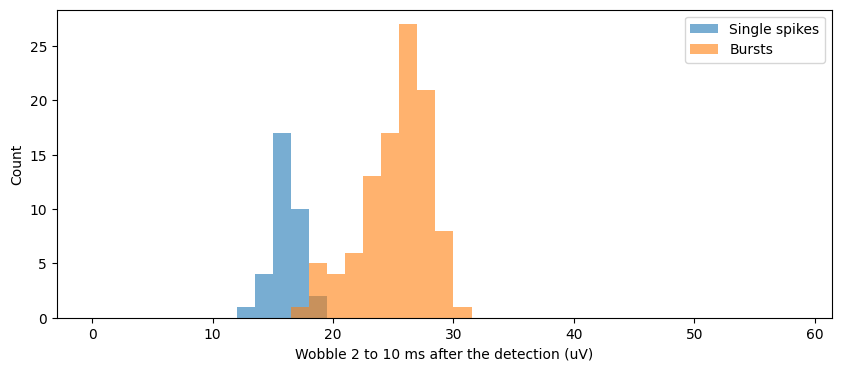

In [4]:
# the answer key for recording A, saved in notebook 03
event_times_a = data_a["event_times"]
event_types_a = data_a["event_types"]
matches_a = match_true_events(event_times_a, detected_events_a)

single_wobbles = []
burst_wobbles = []

for i in range(len(event_times_a)):
    if matches_a[i] == -1:
        continue
    detected_event = detected_events_a[matches_a[i]]

    # only events the chip saw as one detection need the wobble
    if len(detected_event) == 1:
        wobble = wobble_after(chip_signal_a, time_a, detected_event[0])
        if event_types_a[i] == "single":
            single_wobbles.append(wobble)
        else:
            burst_wobbles.append(wobble)

print("one-detection events that are single spikes:", len(single_wobbles))
print("one-detection events that are bursts:       ", len(burst_wobbles))
print("typical wobble, single spikes:", round(np.median(single_wobbles), 1), "uV")
print("typical wobble, bursts:       ", round(np.median(burst_wobbles), 1), "uV")

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 60, 1.5)
ax.hist(single_wobbles, bins=bins, alpha=0.6, label="Single spikes")
ax.hist(burst_wobbles, bins=bins, alpha=0.6, label="Bursts")
ax.set_xlabel("Wobble 2 to 10 ms after the detection (uV)")
ax.set_ylabel("Count")
ax.legend()
plt.show()

In [5]:
# choose the cut-off on recording A, using balanced accuracy
best_cutoff = 0
best_balanced = 0

for cutoff in np.arange(10, 40, 0.5):
    result = score_labels(event_times_a, event_types_a, detected_events_a, chip_signal_a, time_a, cutoff)
    singles_right, singles_total, bursts_right, bursts_total, missed, false_alarms = result

    # the average of "% of singles right" and "% of bursts right"
    balanced = (singles_right / singles_total + bursts_right / bursts_total) / 2

    if balanced > best_balanced:
        best_balanced = balanced
        best_cutoff = cutoff

print("best cut-off:", best_cutoff, "uV")
print("balanced accuracy on recording A:", round(100 * best_balanced, 1), "%")

best cut-off: 18.5 uV
balanced accuracy on recording A: 81.2 %


single spikes labelled right: 23 of 26
bursts labelled right:        131 of 138
events missed: 0 | false alarms: 5
balanced accuracy: 91.7 % (always guessing one type: 50%)
plain accuracy: 93.9 % (always guessing 'burst': 84.1 %)


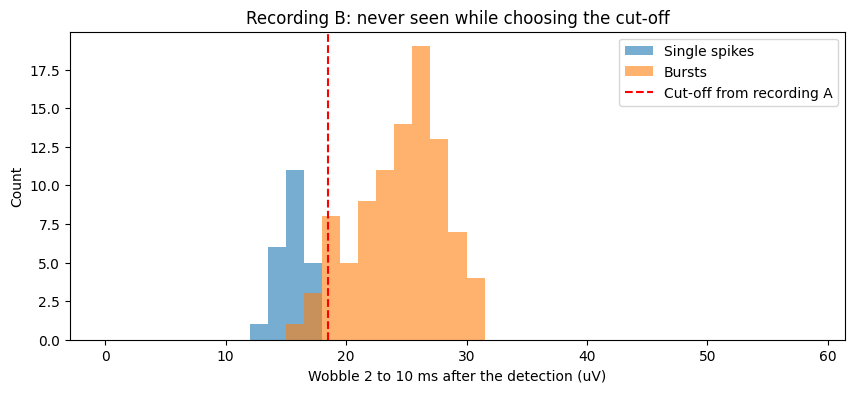

In [12]:
# test recording B: the fresh simulation, never used to choose the cut-off
data_b = np.load("../data/processed/simulation_60s_seed1.npz")
time_b = data_b["time_ms"]
n_samples_b = len(data_b["v_electrode_uV"])

recording_b = (data_b["v_electrode_uV"] + thermal_noise_uV(n_samples_b, dt_ms=0.05, seed=2)
               + background_noise_uV(n_samples_b, dt_ms=0.05, seed=3) + slow_wave_uV(n_samples_b, dt_ms=0.05))
filtered_b = bandpass_filter(recording_b, dt_ms=0.05)
chip_signal_b, step_uV = digitise(filtered_b, n_bits=8, input_range_uV=500.0)
detections_b, threshold_uV = detect_spikes(chip_signal_b, time_b, threshold_factor=4.5, min_gap_ms=3.0)
detected_events_b = group_into_events(detections_b)

# the answer key for recording B
event_times_b = data_b["event_times"]
event_types_b = data_b["event_types"]

result = score_labels(event_times_b, event_types_b, detected_events_b, chip_signal_b, time_b, best_cutoff)
singles_right, singles_total, bursts_right, bursts_total, missed, false_alarms = result

balanced = (singles_right / singles_total + bursts_right / bursts_total) / 2
overall = (singles_right + bursts_right) / (singles_total + bursts_total)
always_burst = bursts_total / (singles_total + bursts_total)

print("single spikes labelled right:", singles_right, "of", singles_total)
print("bursts labelled right:       ", bursts_right, "of", bursts_total)
print("events missed:", missed, "| false alarms:", false_alarms)
print("balanced accuracy:", round(100 * balanced, 1), "% (always guessing one type: 50%)")
print("plain accuracy:", round(100 * overall, 1), "% (always guessing 'burst':", round(100 * always_burst, 1), "%)")

# the wobbles of one-detection events, for the plot
matches_b = match_true_events(event_times_b, detected_events_b)
single_wobbles_b = []
burst_wobbles_b = []
for i in range(len(event_times_b)):
    if matches_b[i] == -1:
        continue
    detected_event = detected_events_b[matches_b[i]]
    if len(detected_event) == 1:
        wobble = wobble_after(chip_signal_b, time_b, detected_event[0])
        if event_types_b[i] == "single":
            single_wobbles_b.append(wobble)
        else:
            burst_wobbles_b.append(wobble)

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 60, 1.5)
ax.hist(single_wobbles_b, bins=bins, alpha=0.6, label="Single spikes")
ax.hist(burst_wobbles_b, bins=bins, alpha=0.6, label="Bursts")
ax.axvline(best_cutoff, color="red", linestyle="--", label="Cut-off from recording A")
ax.set_xlabel("Wobble 2 to 10 ms after the detection (uV)")
ax.set_ylabel("Count")
ax.set_title("Recording B: never seen while choosing the cut-off")
ax.legend()
plt.show()

In [13]:
# test recording C: stronger input, never used to choose the cut-off
data_c = np.load("../data/processed/simulation_60s_input3.npz")
time_c = data_c["time_ms"]
n_samples_c = len(data_c["v_electrode_uV"])

recording_c = (data_c["v_electrode_uV"] + thermal_noise_uV(n_samples_c, dt_ms=0.05, seed=4)
               + background_noise_uV(n_samples_c, dt_ms=0.05, seed=5) + slow_wave_uV(n_samples_c, dt_ms=0.05))
filtered_c = bandpass_filter(recording_c, dt_ms=0.05)
chip_signal_c, step_uV = digitise(filtered_c, n_bits=8, input_range_uV=500.0)
detections_c, threshold_uV = detect_spikes(chip_signal_c, time_c, threshold_factor=4.5, min_gap_ms=3.0)
detected_events_c = group_into_events(detections_c)

# the answer key for recording C
event_times_c = data_c["event_times"]
event_types_c = data_c["event_types"]

result = score_labels(event_times_c, event_types_c, detected_events_c, chip_signal_c, time_c, best_cutoff)
singles_right, singles_total, bursts_right, bursts_total, missed, false_alarms = result

balanced = (singles_right / singles_total + bursts_right / bursts_total) / 2
overall = (singles_right + bursts_right) / (singles_total + bursts_total)
always_burst = bursts_total / (singles_total + bursts_total)

print("cut-off used (from recording A):", best_cutoff, "uV")
print("single spikes labelled right:", singles_right, "of", singles_total)
print("bursts labelled right:       ", bursts_right, "of", bursts_total)
print("events missed:", missed, "| false alarms:", false_alarms)
print("balanced accuracy:", round(100 * balanced, 1), "% (always guessing one type: 50%)")
print("plain accuracy:", round(100 * overall, 1), "% (always guessing 'burst':", round(100 * always_burst, 1), "%)")

cut-off used (from recording A): 18.5 uV
single spikes labelled right: 405 of 677
bursts labelled right:        414 of 414
events missed: 8 | false alarms: 20
balanced accuracy: 79.9 % (always guessing one type: 50%)
plain accuracy: 75.1 % (always guessing 'burst': 37.9 %)


In [14]:
# why are recording C's single spikes labelled wrong?
matches_c = match_true_events(event_times_c, detected_events_c)

wrong_singles_total = 0
in_bigger_group = 0
in_bigger_group_with_other_event = 0
alone_high_wobble = 0
alone_high_wobble_next_close = 0

for i in range(len(event_times_c)):
    # only single spikes that the chip caught
    if event_types_c[i] != "single" or matches_c[i] == -1:
        continue

    detected_event = detected_events_c[matches_c[i]]
    guess = label_event(detected_event, chip_signal_c, time_c, best_cutoff)
    if guess == "single":
        continue
    wrong_singles_total = wrong_singles_total + 1

    if len(detected_event) > 1:
        # cause 1: the group has 2 or more detections
        in_bigger_group = in_bigger_group + 1
        # does this group also hold another true event?
        if matches_c.count(matches_c[i]) > 1:
            in_bigger_group_with_other_event = in_bigger_group_with_other_event + 1
    else:
        # cause 2: alone in the group, but the wobble was too high
        alone_high_wobble = alone_high_wobble + 1
        # did the next true event come within 10 ms (inside the wobble window)?
        if i + 1 < len(event_times_c) and event_times_c[i + 1] - event_times_c[i] <= 10.0:
            alone_high_wobble_next_close = alone_high_wobble_next_close + 1

print("single spikes labelled wrong:", wrong_singles_total)
print("  in a group with 2+ detections:", in_bigger_group)
print("    ...and that group also caught another true event:", in_bigger_group_with_other_event)
print("  alone in their group, but wobble above the cut-off:", alone_high_wobble)
print("    ...and the next true event came within 10 ms:", alone_high_wobble_next_close)

single spikes labelled wrong: 272
  in a group with 2+ detections: 257
    ...and that group also caught another true event: 253
  alone in their group, but wobble above the cut-off: 15
    ...and the next true event came within 10 ms: 3


In [2]:
# control: recording A's input (seed 0), but with the calcium current switched off
input_theory, hidden_state = make_frozen_noise(duration_ms=60000, dt_ms=0.05, seed=0)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05, calcium_mS=0.0)
spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])

# the answer key: Zeldenrust & Wadman (2013) burst rule
event_times, event_types = classify_events(result["v_soma_mV"], result["v_dend_mV"], result["time_ms"])

np.savez(
    "../data/processed/simulation_60s_no_calcium.npz",
    time_ms=result["time_ms"],
    v_soma_mV=result["v_soma_mV"],
    v_dend_mV=result["v_dend_mV"],
    v_electrode_uV=v_electrode_uV,
    spike_times=spike_times,
    spike_heights=spike_heights,
    event_times=event_times,
    event_types=event_types,
)
print("true spikes:", len(spike_times))
print("true events:", len(event_times))
print("bursts:", event_types.count("burst"))
print("single spikes:", event_types.count("single"))

true spikes: 466
true events: 466
bursts: 0
single spikes: 466


typical wobble, noise only:     11.3 uV ( 981 windows )
typical wobble, calcium off:    15.9 uV ( 463 events )
typical wobble, normal singles: 16.2 uV
typical wobble, normal bursts:  25.8 uV
calcium-off events above the cut-off: 8 of 463


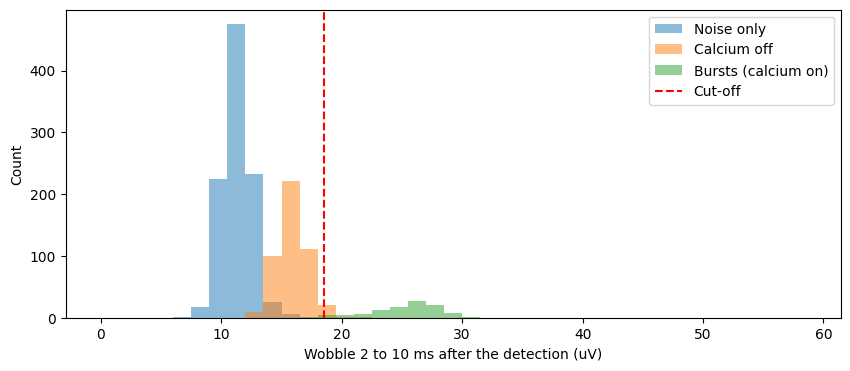

In [6]:
# the calcium-off recording, through the same chip as recording A
data_n = np.load("../data/processed/simulation_60s_no_calcium.npz")
time_n = data_n["time_ms"]
n_samples_n = len(data_n["v_electrode_uV"])

recording_n = (data_n["v_electrode_uV"] + thermal_noise_uV(n_samples_n, dt_ms=0.05)
               + background_noise_uV(n_samples_n, dt_ms=0.05) + slow_wave_uV(n_samples_n, dt_ms=0.05))
filtered_n = bandpass_filter(recording_n, dt_ms=0.05)
chip_signal_n, step_uV = digitise(filtered_n, n_bits=8, input_range_uV=500.0)
detections_n, threshold_uV = detect_spikes(chip_signal_n, time_n, threshold_factor=4.5, min_gap_ms=3.0)
detected_events_n = group_into_events(detections_n)

# wobble after each calcium-off event that the chip saw as one detection
event_times_n = data_n["event_times"]
matches_n = match_true_events(event_times_n, detected_events_n)
no_calcium_wobbles = []
for i in range(len(event_times_n)):
    if matches_n[i] == -1:
        continue
    detected_event = detected_events_n[matches_n[i]]
    if len(detected_event) == 1:
        no_calcium_wobbles.append(wobble_after(chip_signal_n, time_n, detected_event[0]))

# noise floor: windows in recording A with no event within 30 ms
noise_wobbles = []
for window_time in np.arange(100, 59900, 50):
    far_from_events = True
    for event_time in event_times_a:
        if abs(event_time - window_time) < 30:
            far_from_events = False
    if far_from_events:
        noise_wobbles.append(wobble_after(chip_signal_a, time_a, window_time))

print("typical wobble, noise only:    ", round(np.median(noise_wobbles), 1), "uV (", len(noise_wobbles), "windows )")
print("typical wobble, calcium off:   ", round(np.median(no_calcium_wobbles), 1), "uV (", len(no_calcium_wobbles), "events )")
print("typical wobble, normal singles:", round(np.median(single_wobbles), 1), "uV")
print("typical wobble, normal bursts: ", round(np.median(burst_wobbles), 1), "uV")

calcium_off_above_cutoff = 0
for wobble in no_calcium_wobbles:
    if wobble >= best_cutoff:
        calcium_off_above_cutoff = calcium_off_above_cutoff + 1
print("calcium-off events above the cut-off:", calcium_off_above_cutoff, "of", len(no_calcium_wobbles))

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 60, 1.5)
ax.hist(noise_wobbles, bins=bins, alpha=0.5, label="Noise only")
ax.hist(no_calcium_wobbles, bins=bins, alpha=0.5, label="Calcium off")
ax.hist(burst_wobbles, bins=bins, alpha=0.5, label="Bursts (calcium on)")
ax.axvline(best_cutoff, color="red", linestyle="--", label="Cut-off")
ax.set_xlabel("Wobble 2 to 10 ms after the detection (uV)")
ax.set_ylabel("Count")
ax.legend()
plt.show()